# Cohortes, retención, LTV y CAC: qué se puede concluir de datos censurados y heterogéneos

**Perfil:** Estrategia, innovación y venture capital  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Una startup de suscripción quiere saber cuánto vale un cliente (**LTV**) y si conviene su costo de adquisición (**CAC**). Pero las cohortes recientes están **censuradas** (solo se observan unos meses) y los clientes son **heterogéneos** (los frágiles se van pronto, los leales se quedan). ¿Qué errores cometen los atajos comunes y cuánto mejora un modelo que respeta la heterogeneidad?

## Recorrido

1. Generador con verdad conocida: churn por cliente con distribución Beta (modelo *shifted beta-geometric*, sBG).
2. El **triángulo de cohortes** y la curva de retención observada.
3. **Por qué el churn promedio engaña:** la heterogeneidad hace que el riesgo caiga con la edad.
4. **Ajuste por máxima verosimilitud con censura** y extrapolación con solo 12 meses de datos.
5. **LTV descontado** frente a la verdad, y **CAC payback**.
6. **Paradoja de mezcla (Simpson):** retención agregada que mejora sin que nada mejore.
7. **Incertidumbre:** intervalo del LTV por *bootstrap* de clientes.
8. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats, optimize, special

## 2. El mundo verdadero

Cada cliente tiene una probabilidad mensual de cancelar $\theta\sim\text{Beta}(\alpha,\beta)$, **fija en el tiempo** pero distinta entre clientes. Entonces la probabilidad de seguir activo tras $t$ meses es

$$S(t)=\frac{B(\alpha,\beta+t)}{B(\alpha,\beta)},$$

y la población agregada tiene un riesgo que **decrece** con $t$ (los frágiles se van primero). Verdad: $\alpha=0{,}8,\ \beta=3{,}2$ (churn medio $\alpha/(\alpha+\beta)=20\,\%$). 36 cohortes mensuales de 1.000 clientes; la cohorte $c$ se observa durante $T-c$ meses, con $T=36$ (las recientes están censuradas). Margen de contribución 30 USD/mes, descuento mensual 1 %.

In [2]:
ALPHA, BETA, NC, TOT, NCLI = 0.8, 3.2, 36, 36, 1000
MARGEN, DESC = 30.0, 0.01

def S_sbg(t, a=ALPHA, b=BETA): return np.exp(special.betaln(a, b + t) - special.betaln(a, b))

def generar(a, b, rng, ncli=NCLI, nc=NC):
    # vida: numero de meses completos activo (se cobra en t=0,1,...); cancelar tras t con prob theta cada mes
    tri = []
    for c in range(nc):
        theta = rng.beta(a, b, ncli); vida = rng.geometric(theta) - 1            # meses sobrevividos tras el primer cobro
        obs = TOT - c                                                              # edades observables 0..obs-1
        activos = np.array([(vida >= t).sum() for t in range(obs)])
        tri.append(activos)
    return tri

rng = np.random.default_rng(SEED)
tri = generar(ALPHA, BETA, rng)
# triangulo como DataFrame (cohorte x edad)
tab = pd.DataFrame([np.r_[t / NCLI, np.full(TOT - len(t), np.nan)] for t in tri], index=[f"c{c:02d}" for c in range(NC)])
print("Retencion observada, primeras 5 cohortes y edades 0,1,2,3,6,12,24:")
tab.loc[["c00", "c01", "c02", "c10", "c20"], [0, 1, 2, 3, 6, 12, 24]].round(3)

Retencion observada, primeras 5 cohortes y edades 0,1,2,3,6,12,24:


,0,1,2,3,6,12,24
c00,1.0000,0.8040,0.6840,0.5820,0.4200,0.2720,0.1770
c01,1.0000,0.8110,0.6680,0.5740,0.4020,0.2560,0.1660
c02,1.0000,0.8020,0.6750,0.5720,0.4100,0.2590,0.1590
c10,1.0000,0.7820,0.6760,0.5850,0.4180,0.2730,0.1630
c20,1.0000,0.8080,0.6730,0.5990,0.4360,0.2980,NaN


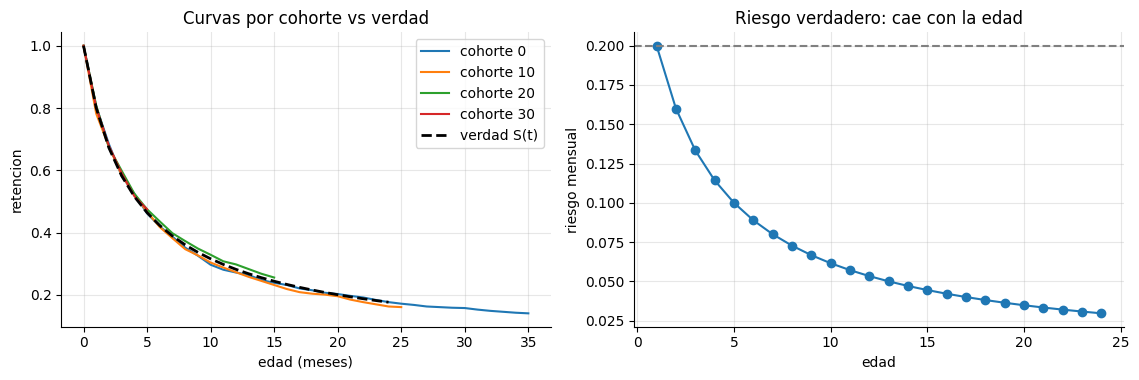

Lectura:
  Riesgo en el mes 1: 20.0%; en el mes 12: 5.3%; en el mes 24: 3.0%. El 'churn promedio' de 20% describe mal a todos: sobreestima el riesgo de los clientes antiguos.
  Retencion verdadera a 12 meses: 28.2%; con churn geometrico constante de 20% seria 6.9%.


In [3]:
ed = np.arange(0, 25)
prom = [np.nanmean(tab[t]) for t in ed]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
for c in (0, 10, 20, 30): ax[0].plot(tab.columns[:len(tri[c])], tab.loc[f"c{c:02d}"].dropna(), label=f"cohorte {c}")
ax[0].plot(ed, S_sbg(ed), "k--", lw=2, label="verdad S(t)"); ax[0].set_xlabel("edad (meses)"); ax[0].set_ylabel("retencion"); ax[0].legend(); ax[0].set_title("Curvas por cohorte vs verdad")
haz = 1 - S_sbg(ed[1:]) / S_sbg(ed[:-1]); ax[1].plot(ed[1:], haz, "o-"); ax[1].axhline(ALPHA / (ALPHA + BETA), ls="--", c="gray"); ax[1].set_xlabel("edad"); ax[1].set_ylabel("riesgo mensual"); ax[1].set_title("Riesgo verdadero: cae con la edad")
plt.tight_layout(); plt.show()
print("Lectura:")
print(f"  Riesgo en el mes 1: {haz[0]:.1%}; en el mes 12: {haz[11]:.1%}; en el mes 24: {haz[23]:.1%}. El 'churn promedio' de 20% describe mal a todos: sobreestima el riesgo de los clientes antiguos.")
print(f"  Retencion verdadera a 12 meses: {S_sbg(12):.1%}; con churn geometrico constante de 20% seria {0.8 ** 12:.1%}.")

## 3. Estimadores y su error

Se comparan tres estrategias para estimar el **valor de vida** (suma descontada del margen, horizonte 60 meses):

1. **Observado truncado:** sumar la retención promedio observada hasta donde hay datos y nada después (subestima).
2. **Churn constante:** estimar el churn medio mensual como *bajas / cliente-mes* y usar una curva geométrica.
3. **sBG por máxima verosimilitud con censura.**

La verosimilitud con censura usa, por cohorte, los activos por edad: las bajas entre $t$ y $t+1$ aportan $\log[S(t)-S(t+1)]$ y los que siguen activos al final de lo observado aportan $\log S(\text{obs}-1)$.

In [4]:
HOR = 60
def ltv_desde_S(S): 
    t = np.arange(HOR); return float((MARGEN * S(t) / (1 + DESC) ** t).sum())

def nll(par, tri_):
    a, b = np.exp(par); out = 0.0
    for act in tri_:
        t = np.arange(len(act)); S = S_sbg(t, a, b); bajas = act[:-1] - act[1:]
        out -= (bajas * np.log(np.maximum(S[:-1] - S[1:], 1e-300))).sum() + act[-1] * np.log(S[-1])
    return out

def ajustar_sbg(tri_):
    r = optimize.minimize(nll, np.log([1.0, 1.0]), args=(tri_,), method="Nelder-Mead", options={"xatol": 1e-6, "fatol": 1e-6, "maxiter": 2000})
    return np.exp(r.x)

def churn_const(tri_):
    bajas = sum((a[:-1] - a[1:]).sum() for a in tri_); expo = sum(a[:-1].sum() for a in tri_)
    return bajas / expo

def estimar(tri_):
    a, b = ajustar_sbg(tri_); ch = churn_const(tri_)
    tmax = 12
    retprom = np.array([np.mean([x[t] / NCLI for x in tri_ if len(x) > t]) for t in range(tmax)])
    trunc = float((MARGEN * retprom / (1 + DESC) ** np.arange(tmax)).sum())
    return {"truncado": trunc, "churn_const": ltv_desde_S(lambda t: (1 - ch) ** t), "sBG": ltv_desde_S(lambda t: S_sbg(t, a, b)), "a": a, "b": b, "ch": ch}

LTV_VERDAD = ltv_desde_S(S_sbg)
est = estimar(tri)
print(f"LTV verdadero (60 meses, descontado): {LTV_VERDAD:,.1f} USD")
print(pd.Series({k: est[k] for k in ("truncado", "churn_const", "sBG")}).to_frame("LTV").assign(error_pct=lambda d: 100 * (d.LTV / LTV_VERDAD - 1)).round(2))
print(f"parametros sBG: alpha={est['a']:.3f} (verdad {ALPHA}), beta={est['b']:.3f} (verdad {BETA})")

LTV verdadero (60 meses, descontado): 336.3 USD
                 LTV  error_pct
truncado    176.4500   -47.5300
churn_const 270.2500   -19.6400
sBG         336.5400     0.0700
parametros sBG: alpha=0.789 (verdad 0.8), beta=3.118 (verdad 3.2)


In [5]:
# Replicas: error de cada estimador con TODA la historia, y con solo 12 meses de datos (extrapolar)
def recortar(tri_, m): return [a[:m] for a in tri_]
filas = []
for r in range(30):
    t_ = generar(ALPHA, BETA, np.random.default_rng(100 + r))
    for nombre, tt in (("historia completa", t_), ("solo 12 meses", recortar(t_, 12))):
        e = estimar(tt); filas.append({"datos": nombre, **{k: 100 * (e[k] / LTV_VERDAD - 1) for k in ("truncado", "churn_const", "sBG")}})
rep = pd.DataFrame(filas).groupby("datos").agg(["mean", "std"]).round(2)
rep

truncado        churn_const            sBG       
                      mean    std        mean    std    mean    std
datos                                                              
historia completa -47.3000 0.1900    -19.4700 0.4400 -0.1300 0.5200
solo 12 meses     -47.3000 0.1900    -33.0200 0.3900 -0.2900 0.7600

In [6]:
sub = pd.DataFrame(filas)
med = sub.groupby("datos").mean().loc[["historia completa", "solo 12 meses"]]
print("Lectura (error porcentual medio del LTV en 30 replicas):")
print(med.round(1).to_string())
print(f"  El truncado subestima siempre (ignora la cola): {med.loc['historia completa', 'truncado']:.0f}% con la historia completa.")
print(f"  El churn constante {'SUBESTIMA' if med.loc['solo 12 meses', 'churn_const'] < 0 else 'SOBREESTIMA'} el LTV en {abs(med.loc['solo 12 meses', 'churn_const']):.0f}%: no capta que los sobrevivientes son los leales.")
print(f"  sBG con solo 12 meses de datos queda a {abs(med.loc['solo 12 meses', 'sBG']):.1f}% de la verdad (desvio {sub[sub.datos == 'solo 12 meses'].sBG.std():.1f} pp).")

Lectura (error porcentual medio del LTV en 30 replicas):
                   truncado  churn_const     sBG
datos                                           
historia completa  -47.3000     -19.5000 -0.1000
solo 12 meses      -47.3000     -33.0000 -0.3000
  El truncado subestima siempre (ignora la cola): -47% con la historia completa.
  El churn constante SUBESTIMA el LTV en 33%: no capta que los sobrevivientes son los leales.
  sBG con solo 12 meses de datos queda a 0.3% de la verdad (desvio 0.8 pp).


## 4. CAC payback y razón LTV/CAC

El **payback** es el mes en que el margen acumulado (no descontado) cubre el CAC; la razón **LTV/CAC** usa el LTV descontado. Con la verdad conocida se calculan para varios CAC y se ve cuánto cambian las decisiones según el estimador de LTV usado (umbral habitual: LTV/CAC ≥ 3).

In [7]:
t = np.arange(HOR); acum = np.cumsum(MARGEN * S_sbg(t))
def payback(cac): 
    i = np.argmax(acum >= cac); return int(i) if acum[i] >= cac else None
filas = []
for cac in (30, 60, 100, 150, 250):
    filas.append({"CAC": cac, "payback_meses": payback(cac), "LTV/CAC_verdad": LTV_VERDAD / cac, "LTV/CAC_churn_const": ltv_desde_S(lambda t: (1 - est['ch']) ** t) / cac, "LTV/CAC_sBG": est["sBG"] / cac})
pb = pd.DataFrame(filas).set_index("CAC"); pb.round(2)

,payback_meses,LTV/CAC_verdad,LTV/CAC_churn_const,LTV/CAC_sBG
CAC,,,,
30,0,11.2100,9.0100,11.2200
60,2,5.6000,4.5000,5.6100
100,4,3.3600,2.7000,3.3700
150,8,2.2400,1.8000,2.2400
250,21,1.3500,1.0800,1.3500


In [8]:
umbral = pb[pb["LTV/CAC_verdad"] >= 3].index.max()
print("Lectura:")
print(f"  Con la verdad, el CAC maximo que cumple LTV/CAC>=3 es {LTV_VERDAD / 3:,.0f} USD; con CAC={umbral} el payback es {payback(umbral)} meses.")
print(f"  El payback con retencion decreciente es MAS LARGO que el ingenuo CAC/margen: con CAC=100 el ingenuo da {100 / MARGEN:.1f} meses y el real {payback(100)}.")
dis = pb[(pb['LTV/CAC_verdad'] >= 3) != (pb['LTV/CAC_churn_const'] >= 3)].index.tolist()
print(f"  Los CAC donde el churn constante y la verdad discrepan en la decision de umbral 3x: {dis if dis else 'ninguno'}.")

Lectura:
  Con la verdad, el CAC maximo que cumple LTV/CAC>=3 es 112 USD; con CAC=100 el payback es 4 meses.
  El payback con retencion decreciente es MAS LARGO que el ingenuo CAC/margen: con CAC=100 el ingenuo da 3.3 meses y el real 4.
  Los CAC donde el churn constante y la verdad discrepan en la decision de umbral 3x: [100].


## 5. Paradoja de mezcla (Simpson)

Dos canales: **pago** (churn alto, $\alpha=1{,}0,\beta=2{,}0$, churn medio 33 %) y **orgánico** (churn bajo, $\alpha=0{,}6,\beta=5{,}4$, churn medio 10 %). La retención **de cada canal es constante en el tiempo**, pero el peso del canal orgánico sube del 10 % al 60 % a lo largo de 24 cohortes. La retención agregada a 6 meses *mejora*, aunque nada ha mejorado.

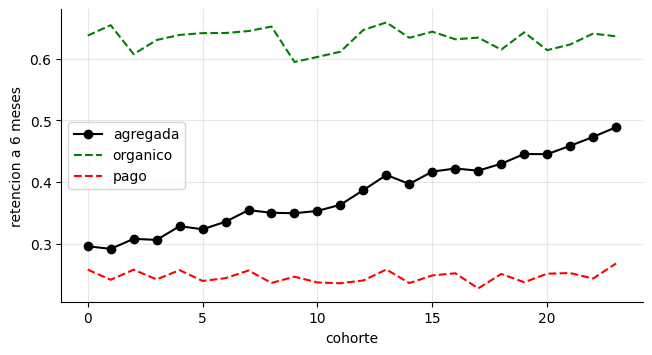

Lectura:
  Retencion agregada a 6 meses: 29.9% (primeras cohortes) -> 47.4% (ultimas): sube 17.5 pp.
  Pendiente por cohorte: agregada +0.0083; organico -0.0002; pago +0.0000 (los canales no cambian).
  Celebrar la mejora agregada seria un error: es mezcla. Hay que segmentar por canal antes de atribuir mejoras al producto.


In [9]:
CAN = {"pago": (1.0, 2.0), "organico": (0.6, 5.4)}
NCOH, N = 24, 4000
peso_org = np.linspace(0.10, 0.60, NCOH); rng = np.random.default_rng(7)
fil = []
for c in range(NCOH):
    n_org = int(N * peso_org[c]); n_pag = N - n_org
    for nom, n in (("organico", n_org), ("pago", n_pag)):
        a, b = CAN[nom]; vida = rng.geometric(rng.beta(a, b, n)) - 1
        fil.append({"cohorte": c, "canal": nom, "n": n, "ret6": (vida >= 6).mean()})
ft = pd.DataFrame(fil)
agg = ft.groupby("cohorte").apply(lambda d: np.average(d.ret6, weights=d.n))
por_canal = ft.pivot(index="cohorte", columns="canal", values="ret6")
fig, ax = plt.subplots(figsize=(7.5, 3.8)); ax.plot(agg.index, agg, "k-o", label="agregada"); ax.plot(por_canal.index, por_canal["organico"], "g--", label="organico"); ax.plot(por_canal.index, por_canal["pago"], "r--", label="pago")
ax.set_xlabel("cohorte"); ax.set_ylabel("retencion a 6 meses"); ax.legend(); plt.show()
pend = lambda y: np.polyfit(por_canal.index, y, 1)[0]
print("Lectura:")
print(f"  Retencion agregada a 6 meses: {agg.iloc[:3].mean():.1%} (primeras cohortes) -> {agg.iloc[-3:].mean():.1%} (ultimas): sube {100 * (agg.iloc[-3:].mean() - agg.iloc[:3].mean()):.1f} pp.")
print(f"  Pendiente por cohorte: agregada {pend(agg):+.4f}; organico {pend(por_canal['organico']):+.4f}; pago {pend(por_canal['pago']):+.4f} (los canales no cambian).")
print("  Celebrar la mejora agregada seria un error: es mezcla. Hay que segmentar por canal antes de atribuir mejoras al producto.")

## 6. Incertidumbre del LTV por *bootstrap* de clientes

Con una sola cohorte reciente de 1.000 clientes y 12 meses de datos, ¿qué tan incierto es el LTV? Se remuestrean los clientes (su vida observada) y se reajusta sBG. Se verifica la **cobertura** del intervalo con el mundo verdadero.

In [10]:
def vidas_cens(n, a, b, obs, rng):
    v = rng.geometric(rng.beta(a, b, n)) - 1; return np.minimum(v, obs - 1), v >= obs - 1          # vida observada, indicador de censura

def tri_desde_vidas(vida, cens, obs):
    return [np.array([(vida >= t).sum() for t in range(obs)])]

def ltv_sbg_vidas(vida, cens, obs):
    a, b = ajustar_sbg(tri_desde_vidas(vida, cens, obs)); return ltv_desde_S(lambda t: S_sbg(t, a, b))

cubre, anchos, puntos = 0, [], []
rng = np.random.default_rng(55); R = 40; B = 60; OBS = 12
for r in range(R):
    vida, cens = vidas_cens(1500, ALPHA, BETA, OBS, rng); p = ltv_sbg_vidas(vida, cens, OBS); puntos.append(p)
    bs = []
    for _ in range(B):
        idx = rng.integers(0, len(vida), len(vida)); bs.append(ltv_sbg_vidas(vida[idx], cens[idx], OBS))
    lo, hi = np.percentile(bs, [5, 95]); cubre += lo <= LTV_VERDAD <= hi; anchos.append((hi - lo) / p)
print(f"Cobertura del intervalo bootstrap 90% sobre {R} replicas: {cubre / R:.0%}; ancho relativo medio: {np.mean(anchos):.0%}; sesgo medio del punto: {100 * (np.mean(puntos) / LTV_VERDAD - 1):+.1f}%")

Cobertura del intervalo bootstrap 90% sobre 40 replicas: 88%; ancho relativo medio: 13%; sesgo medio del punto: +0.9%


In [11]:
print("Lectura:")
print(f"  Con 1.500 clientes y 12 meses el intervalo del 90% mide ~{np.mean(anchos):.0%} del LTV estimado, incluso con el modelo correcto; con cohortes mas pequenas el ancho crece, porque la cola se extrapola.")
print(f"  La cobertura empirica ({cubre / R:.0%}) es la prueba de que el intervalo es creible; un intervalo con cobertura muy inferior a 90% subestimaria el riesgo.")

Lectura:
  Con 1.500 clientes y 12 meses el intervalo del 90% mide ~13% del LTV estimado, incluso con el modelo correcto; con cohortes mas pequenas el ancho crece, porque la cola se extrapola.
  La cobertura empirica (88%) es la prueba de que el intervalo es creible; un intervalo con cobertura muy inferior a 90% subestimaria el riesgo.


## 7. Pruebas automáticas

In [12]:
# 7.1 S(0)=1, monotona decreciente, coincide con la formula de la media geometrica de una Beta por simulacion
assert abs(S_sbg(0) - 1) < 1e-12 and (np.diff(S_sbg(np.arange(40))) < 0).all()
th = np.random.default_rng(3).beta(ALPHA, BETA, 400_000); assert abs(((1 - th) ** 12).mean() - S_sbg(12)) < 3e-3
# 7.2 el riesgo verdadero es decreciente en la edad (heterogeneidad) y menor que el churn medio al final
assert (np.diff(haz) < 0).all() and haz[-1] < ALPHA / (ALPHA + BETA)
# 7.3 el sBG recupera los parametros con toda la historia; el triangulo observado tiene la forma esperada
assert abs(est["a"] - ALPHA) / ALPHA < 0.25 and abs(est["b"] - BETA) / BETA < 0.25 and len(tri[0]) == 36 and len(tri[-1]) == 1
# 7.4 truncado subestima; churn constante subestima el LTV extrapolando 12 meses; sBG queda cerca
assert (sub.truncado < 0).all()
assert med.loc["solo 12 meses", "churn_const"] < -10 and abs(med.loc["solo 12 meses", "sBG"]) < 8
assert abs(med.loc["historia completa", "sBG"]) < 4
# 7.5 payback: monotono en el CAC y mayor que el ingenuo CAC/margen
assert pb["payback_meses"].dropna().is_monotonic_increasing and payback(100) > 100 / MARGEN
# 7.6 Simpson: agregada sube, pendiente por canal ~0
assert agg.iloc[-3:].mean() - agg.iloc[:3].mean() > 0.08 and abs(pend(por_canal["organico"])) < 0.004 and abs(pend(por_canal["pago"])) < 0.004
# 7.7 bootstrap: cobertura razonable
assert cubre / R >= 0.75
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Heterogeneidad | El riesgo agregado cae con la edad porque los frágiles se van primero | Modelar retención con mezcla, no con un churn único |
| Censura | Las cohortes recientes están incompletas; truncar subestima el LTV | Usar verosimilitud con censura |
| Extrapolación | Con 12 meses, el churn constante subestima sustancialmente el LTV; sBG queda cerca | Preferir modelos que capturen la heterogeneidad |
| Payback | Con retención decreciente el payback real es mayor que CAC/margen | Calcular el payback sobre la curva de retención |
| Mezcla | Una mejora agregada puede ser solo cambio de canales | Segmentar antes de atribuir mejoras |
| Incertidumbre | El intervalo del LTV es ancho aun con el modelo correcto | Reportar intervalos, no un punto |

**Límites que no deben ocultarse**

- El modelo sBG supone churn fijo por cliente y ausencia de reactivaciones; el producto real tiene cambios de plan, estacionalidad y efectos de precio.
- El margen se supone constante por cliente activo; en la práctica crece (expansión) o decae (descuentos).
- Datos sintéticos: los porcentajes concretos no son extrapolables a un negocio real.